#### Alessia Stefanelli - 615430

# Data Understanding - Time Series ECG


In [1]:
import os
import zipfile
import wfdb
import pandas as pd
import random
import matplotlib.pyplot as plt
import numpy as np

Estrapolazione dal file zip dei path ECG validi

In [2]:
base_zip_dir = "../datasets/time-series.zip"
base_dir = "time-series/"
output_dir = "../datasets/valid_time-series/"

valid_directories = []
with zipfile.ZipFile(base_zip_dir, 'r') as zip_ref:
    zip_files = zip_ref.namelist()
    for patient_folder in set(os.path.dirname(f) for f in zip_files if f.startswith(base_dir)):
        has_dat = any(f.endswith(".dat") and f.startswith(patient_folder) for f in zip_files)
        has_hea = any(f.endswith(".hea") and f.startswith(patient_folder) for f in zip_files)
        if has_dat and has_hea:
            valid_directories.append(patient_folder)

In [12]:
valid_directories

['time-series/10039709_48212074',
 'time-series/10272425_42750573',
 'time-series/10168400_44373176',
 'time-series/10086652_47485224',
 'time-series/10069992_43930543',
 'time-series/10248032_41514780',
 'time-series/10253119_46275759',
 'time-series/10074282_47658088',
 'time-series/10199636_48404825',
 'time-series/10258020_44578511',
 'time-series/10168562_42990530',
 'time-series/10159319_49745229',
 'time-series/10129617_47870668',
 'time-series/10173705_41077804',
 'time-series/10007058_47527771',
 'time-series/10239261_43999292',
 'time-series/10067149_49369118',
 'time-series/10223996_49656997',
 'time-series/10100035_49092884',
 'time-series/10053564_40022469',
 'time-series/10136839_44753520',
 'time-series/10268967_40245463',
 'time-series/10116085_46017293',
 'time-series/10261569_48783407',
 'time-series/10016742_40747565',
 'time-series/10088799_40123236',
 'time-series/10132139_48456638',
 'time-series/10119391_41578459',
 'time-series/10205923_45271900',
 'time-series/

#### Creazione cartella con gli ECG validi

In [5]:
with zipfile.ZipFile(base_zip_dir, 'r') as zip_ref:
    for valid_dir in valid_directories:
        for file in zip_files:
            if file.startswith(valid_dir) and (file.endswith(".dat") or file.endswith(".hea")):
                output_path = os.path.join(output_dir, os.path.normpath(os.path.relpath(file, base_dir)))
                dir_path = os.path.dirname(output_path)
                if not os.path.isfile(dir_path):
                    os.makedirs(dir_path, exist_ok=True)
                if not os.path.exists(output_path):
                    with zip_ref.open(file) as src, open(output_path, 'wb') as dst:
                        dst.write(src.read())

print(f"Numero di directory valide: {len(valid_directories)-1}")
print("I file .dat e .hea validi sono stati estratti in:", output_dir)


Numero di directory valide: 1100
I file .dat e .hea validi sono stati estratti in: ../datasets/valid_time-series/


### Conversion of *.dat* and *.hea* Files into *.csv*

In [8]:
# Percorso della directory con i file .dat e .hea
input_dir = "../datasets/valid_time-series/"
output_dir = "../datasets/valid_time-series-csv/"

os.makedirs(output_dir, exist_ok=True) 
success_conv = 0
for root, _, files in os.walk(input_dir):
    for file in files:
        if file.endswith(".hea"):
            record_name = os.path.splitext(file)[0]
            file_path = os.path.join(root, record_name)
            record = wfdb.rdrecord(file_path)
            dir_name = os.path.basename(root)
            signals_df = pd.DataFrame(record.p_signal, columns=record.sig_name)
            output_csv = os.path.join(output_dir, f"{dir_name}.csv")
            signals_df.to_csv(output_csv, index=False)
            success_conv += 1
print(f"Total success conversion: {success_conv}")

Total success conversion: 1100


### CSV File analysis

Analisi della struttura del file .csv su un file csv preso a caso.  

In [17]:
output_dir = "../datasets/valid_time-series-csv/"

csv_files = [f for f in os.listdir(output_dir) if f.endswith(".csv")]

random_files = random.sample(csv_files, min(3, len(csv_files)))
random_file_list = []
for file_name in random_files:
    file_path = os.path.join(output_dir, file_name)
    random_file_list.append(file_path)
    df = pd.read_csv(file_path)
    print(f"File: {file_name}")
    print(f"Numero di righe: {len(df)}")
    print("Contenuto del file:")
    print(df.head(), "\n")


File: 10067195_40634663.csv
Numero di righe: 5000
Contenuto del file:
      I    II   III   aVR   aVF   aVL    V1    V2    V3    V4    V5    V6
0 -0.04 -0.02  0.00  0.02  0.00 -0.02  0.00 -0.10 -0.02 -0.02 -0.02 -0.02
1 -0.06 -0.04  0.00  0.04 -0.02 -0.02 -0.02 -0.12 -0.02 -0.02 -0.02 -0.02
2 -0.06 -0.06  0.00  0.04 -0.02 -0.02 -0.02 -0.14 -0.02 -0.04 -0.04 -0.02
3 -0.06 -0.06 -0.02  0.06 -0.04 -0.02 -0.02 -0.14 -0.04 -0.04 -0.04 -0.02
4 -0.06 -0.06 -0.02  0.06 -0.04 -0.02 -0.02 -0.16 -0.04 -0.04 -0.04 -0.02 

File: 10070701_48420484.csv
Numero di righe: 5000
Contenuto del file:
       I     II    III    aVR    aVF    aVL     V1     V2    V3     V4     V5  \
0  0.020 -0.040 -0.065  0.010 -0.050  0.040  0.000 -0.010 -0.02 -0.010  0.005   
1  0.005 -0.035 -0.045  0.015 -0.035  0.025  0.010 -0.010 -0.01 -0.005  0.025   
2  0.000 -0.035 -0.040  0.015 -0.035  0.020  0.015 -0.005  0.00 -0.005  0.035   
3  0.000 -0.040 -0.045  0.020 -0.040  0.020  0.020 -0.005  0.01 -0.005  0.025   
4 -0.010 

https://www.zoll.com/-/media/public-site/products/m-series-defibrillator/9650-0218-02_revb.ashx#:~:text=L'ECG%2012%20d%C3%A9rivations%20est,cardiaques%20transitoires%20qui%20peuvent%20survenir.
Segnali identificati (12 derivazioni):
- Arti:
    1. `I`, 
    2. `II`, 
    3. `III`
    4. `aVR`
    5. `aVF`
    6. `aVL`
- Petto:
    7. `V1` 
    8. `V2`
    9. `V3`
    10. `V4`
    11. `V5`
    12. `V6`

#### Plot of the lead signals of 3 random selected ECG

Plot grafica dei segnali

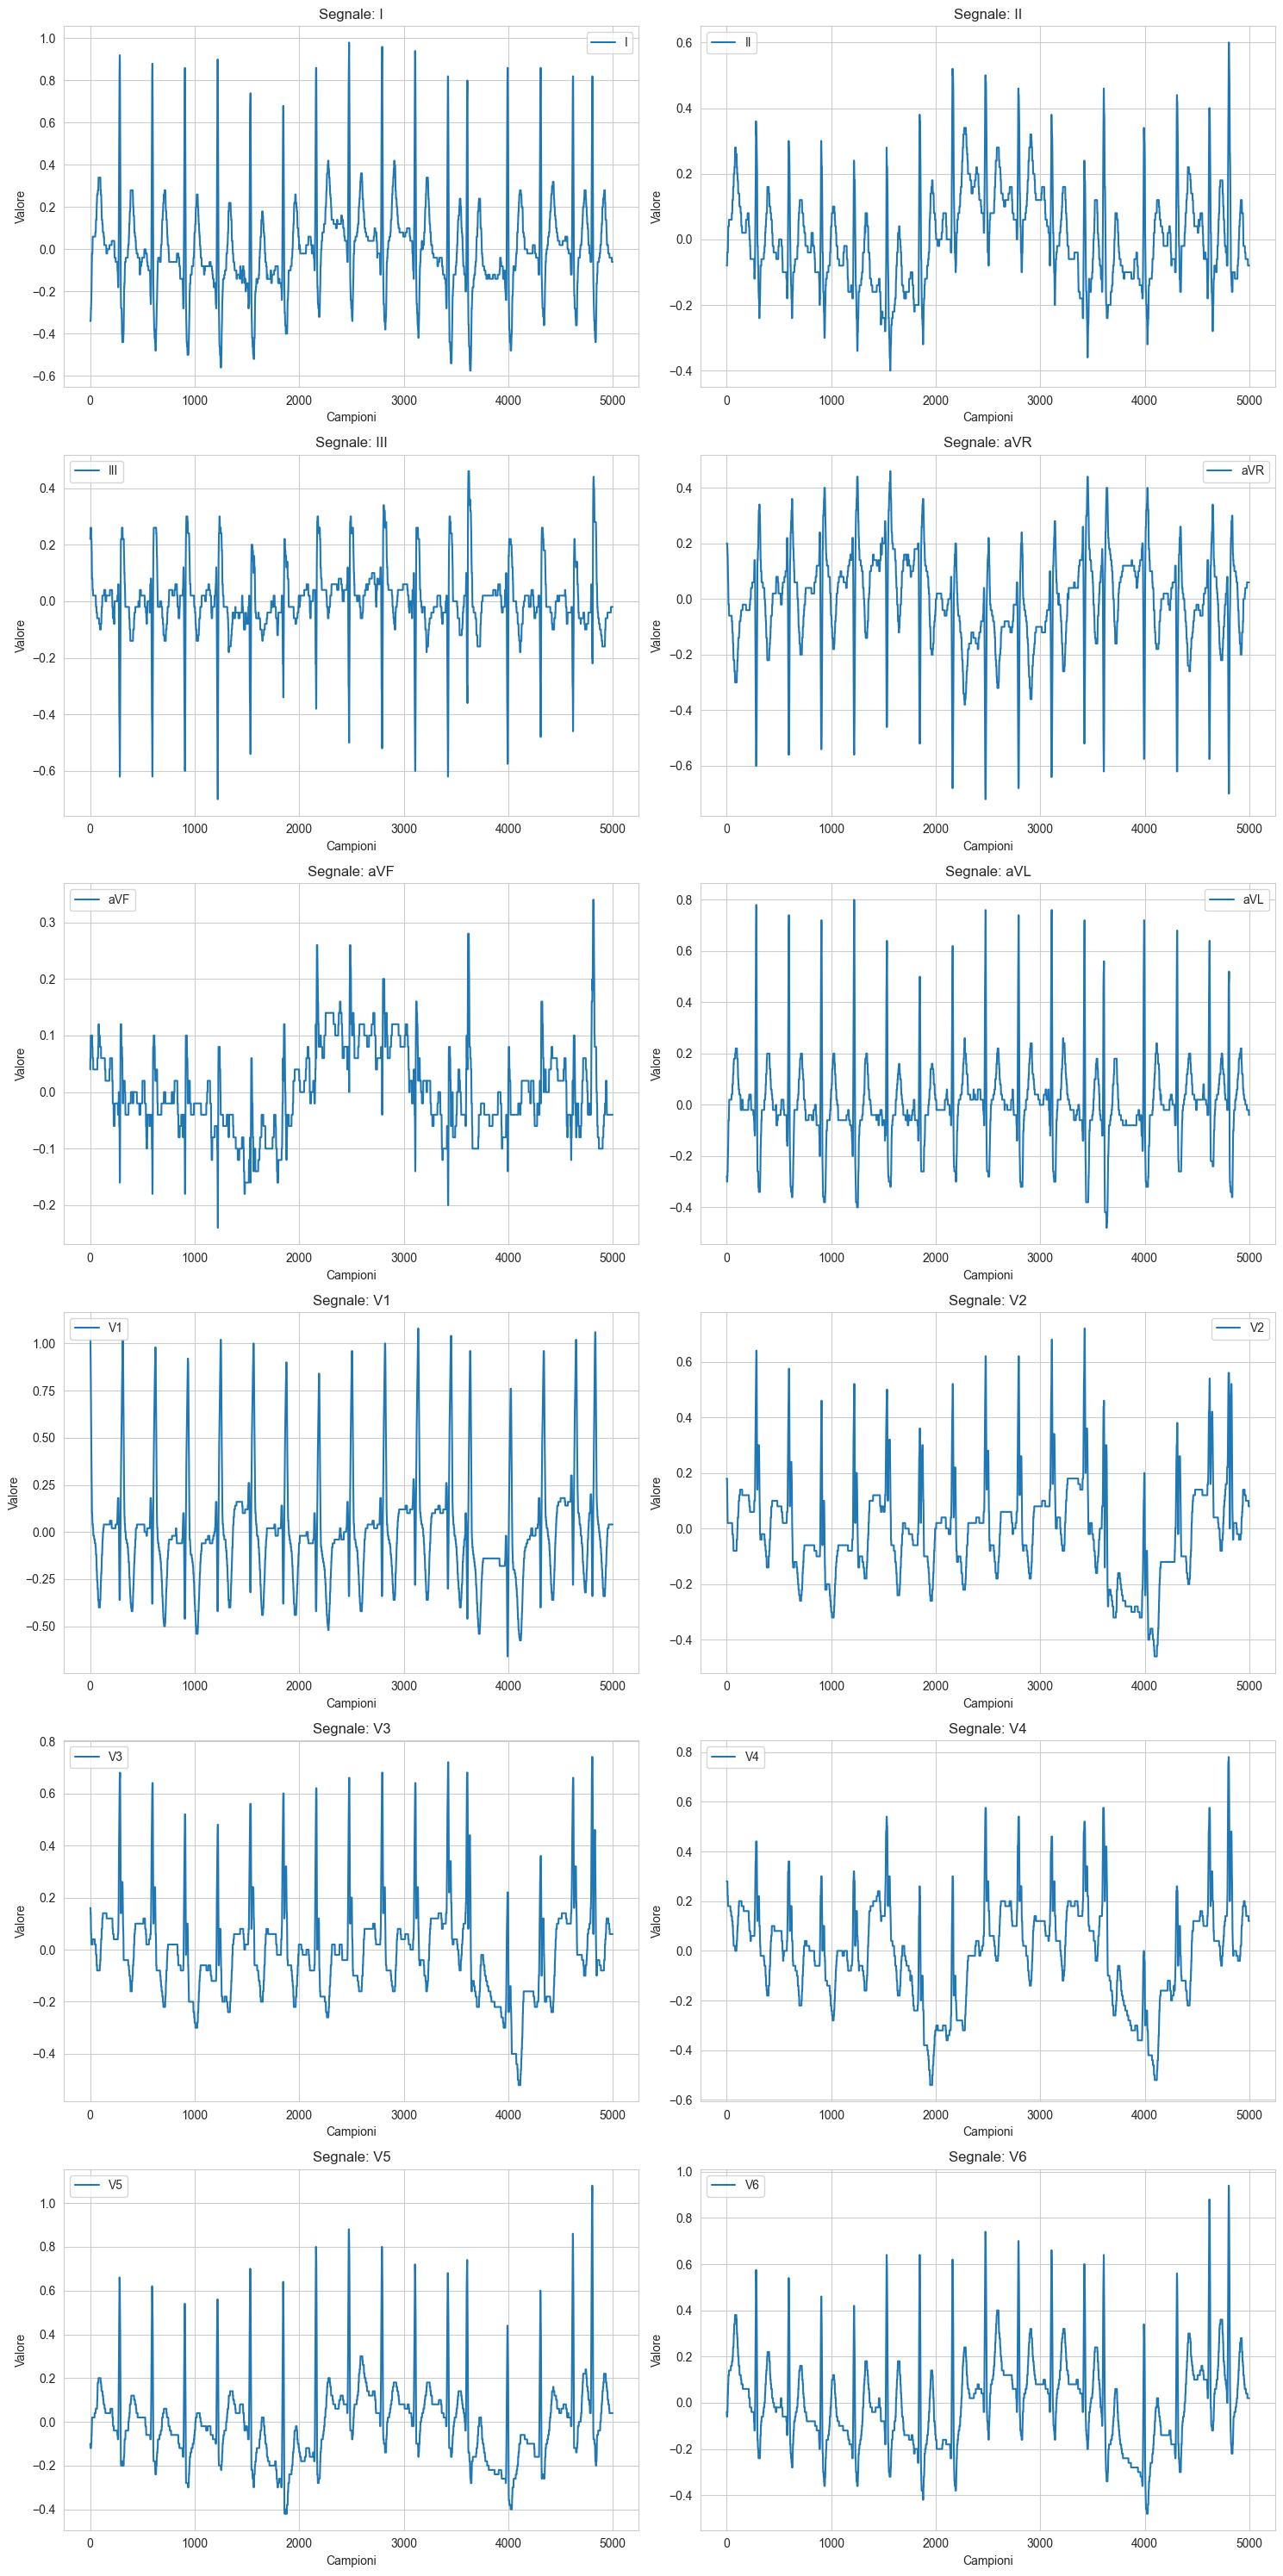

In [14]:
file_path = "../datasets/valid_time-series-csv/10057731_49126185.csv"
df = pd.read_csv(file_path)

plots_per_row = 2
num_columns = len(df.columns)
num_rows = -(-num_columns // plots_per_row)  # Ceiling division
fig, axes = plt.subplots(num_rows, plots_per_row, figsize=(15, num_rows * 5))
axes = axes.flatten()  # Flatten axes for easy iteration
for idx, column in enumerate(df.columns):
    ax = axes[idx]
    ax.plot(df[column], label=column)
    ax.set_title(f"Segnale: {column}")
    ax.set_xlabel("Campioni")
    ax.set_ylabel("Valore")
    ax.legend()
    ax.grid(True)
for idx in range(len(df.columns), len(axes)):
    fig.delaxes(axes[idx])
plt.tight_layout()
plt.show()


Informazioni Dettagliate del Record:
Patient Directory: 10067195_40634663
Study ID: 40634663
Sampling Frequency: 500 Hz
Leads: ['I', 'II', 'III', 'aVR', 'aVF', 'aVL', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Record Length (seconds): 10.0
Signal Units: ['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV']
Base Time: 03:47:00
Base Date: 2181-08-27
Comments: ['<subject_id>: 10067195']



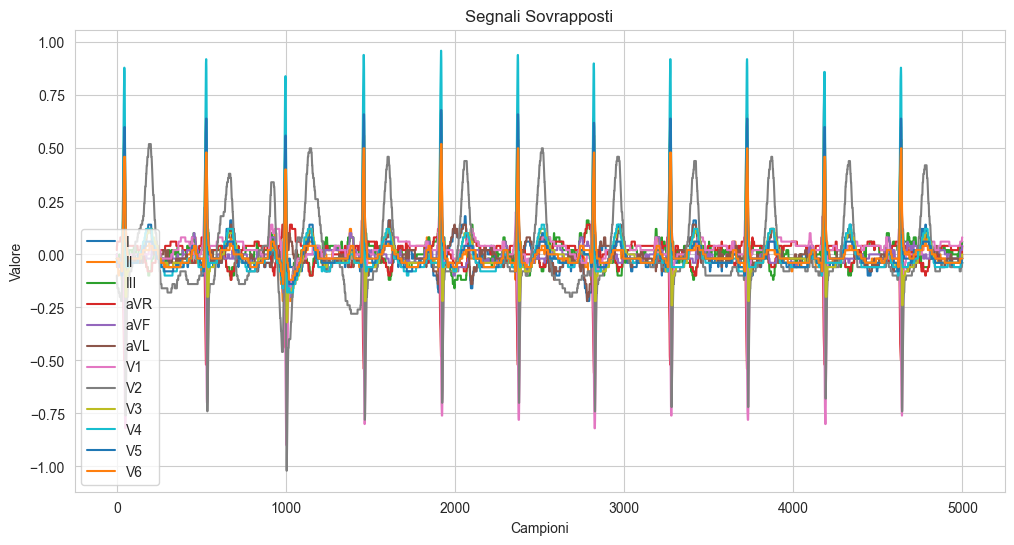

Informazioni Dettagliate del Record:
Patient Directory: 10070701_48420484
Study ID: 48420484
Sampling Frequency: 500 Hz
Leads: ['I', 'II', 'III', 'aVR', 'aVF', 'aVL', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Record Length (seconds): 10.0
Signal Units: ['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV']
Base Time: 16:10:00
Base Date: 2156-10-02
Comments: ['<subject_id>: 10070701']



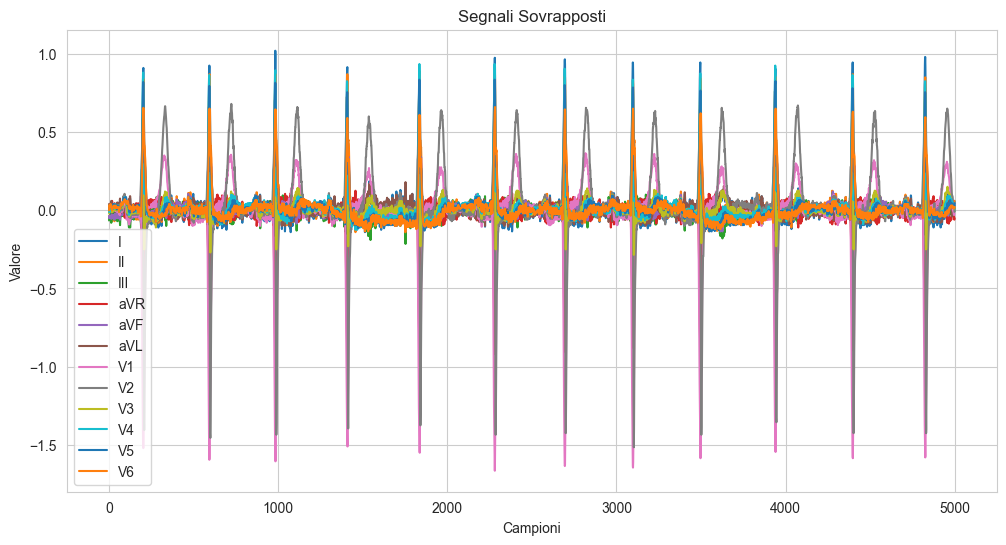

Informazioni Dettagliate del Record:
Patient Directory: 10049778_49049006
Study ID: 49049006
Sampling Frequency: 500 Hz
Leads: ['I', 'II', 'III', 'aVR', 'aVF', 'aVL', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Record Length (seconds): 10.0
Signal Units: ['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV']
Base Time: 06:09:00
Base Date: 2135-11-02
Comments: ['<subject_id>: 10049778']



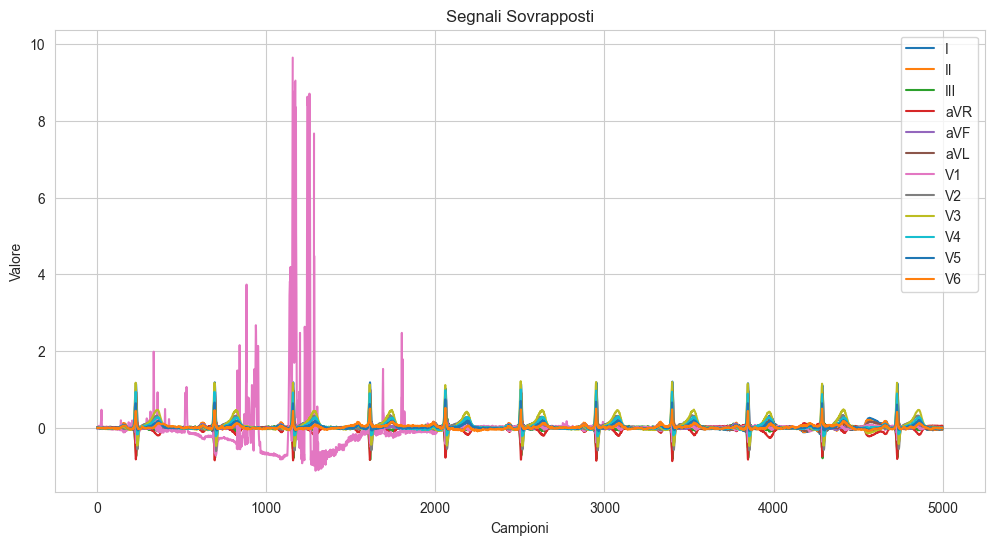

In [18]:
for file in random_file_list:
    df = pd.read_csv(file)
    patient_dir = file.split('/')[-1].replace('.csv', '') 
    study_stay_id = file.split('/')[-1].split('_')
    study_stay_id[1] = study_stay_id[1].replace('.csv', '')
    record_path = os.path.join(input_dir, patient_dir, study_stay_id[1])

    record = wfdb.rdrecord(f"{record_path}")

    print("Informazioni Dettagliate del Record:")
    print(f"Patient Directory: {patient_dir}")
    print(f"Study ID: {study_stay_id[1]}")
    print(f"Sampling Frequency: {record.fs} Hz")
    print(f"Leads: {record.sig_name}")
    print(f"Record Length (seconds): {len(record.p_signal) / record.fs}")
    print(f"Signal Units: {record.units}")
    print(f"Base Time: {record.base_time}")
    print(f"Base Date: {record.base_date}")
    print(f"Comments: {record.comments}")
    print()
    plt.figure(figsize=(12, 6))
    for column in df.columns:
        plt.plot(df[column], label=column)
    plt.title("Segnali Sovrapposti")
    plt.xlabel("Campioni")
    plt.ylabel("Valore")
    plt.legend()
    plt.grid(True)
    plt.show()
